# Pratical Assignment 2

## Part I: Reconstruction and Denoising Using Autoencoders

### Objective

The objective of Part I is to define a suitable network composed by encoder and decoder architectures to process Kuzushiji-MNIST images. You will implement an Autoencoder (AE), a Variational Autoencoder (VAE) and a Denoising Autoencoder (DAE).

In [ ]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt


### 1.1 Autoencoder Network (AE)

fazer a mais facil de se fazer
You can use a fully-connected-based encoder-decoder, however a convolution-based encoder-decoder will be
valued.

In [2]:
tensor_transform = transforms.ToTensor()

train_dataset = datasets.KMNIST(
    root="./data", 
    train=True, 
    download=True, 
    transform=tensor_transform
)

train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset, 
    batch_size=32, 
    shuffle=True
)

test_dataset = datasets.KMNIST(
    root="./data", 
    train=False, 
    download=True, 
    transform=tensor_transform
)

test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset, 
    batch_size=32, 
    shuffle=False
)

100.0%
100.0%
100.0%
100.0%


In [3]:
class AE(nn.Module):
    def __init__(self):
        super(AE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 36),
            nn.ReLU(),
            nn.Linear(36, 18),
            nn.ReLU(),
            nn.Linear(18, 9)
        )
        self.decoder = nn.Sequential(
            nn.Linear(9, 18),
            nn.ReLU(),
            nn.Linear(18, 36),
            nn.ReLU(),
            nn.Linear(36, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [4]:
model = AE()
loss_function = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-8)

Epoch 1/20, Loss: 0.068891
Epoch 2/20, Loss: 0.074785
Epoch 3/20, Loss: 0.062576
Epoch 4/20, Loss: 0.064249
Epoch 5/20, Loss: 0.059095
Epoch 6/20, Loss: 0.048868
Epoch 7/20, Loss: 0.055773
Epoch 8/20, Loss: 0.053268
Epoch 9/20, Loss: 0.052419
Epoch 10/20, Loss: 0.049324
Epoch 11/20, Loss: 0.061271
Epoch 12/20, Loss: 0.051744
Epoch 13/20, Loss: 0.046053
Epoch 14/20, Loss: 0.054677
Epoch 15/20, Loss: 0.056784
Epoch 16/20, Loss: 0.052244
Epoch 17/20, Loss: 0.051012
Epoch 18/20, Loss: 0.056330
Epoch 19/20, Loss: 0.056163
Epoch 20/20, Loss: 0.051575


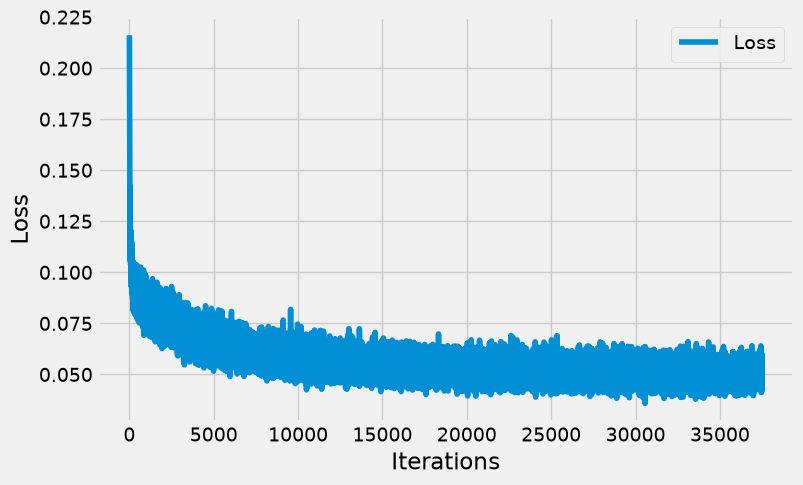

In [6]:
epochs = 20
outputs = []
losses = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

for epoch in range(epochs):
    for images, _ in train_loader:
        images = images.view(-1, 28 * 28).to(device)
        
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())
    
    outputs.append((epoch, images, reconstructed))
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.6f}")

plt.style.use('fivethirtyeight')
plt.figure(figsize=(8, 5))
plt.plot(losses, label='Loss')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.show()

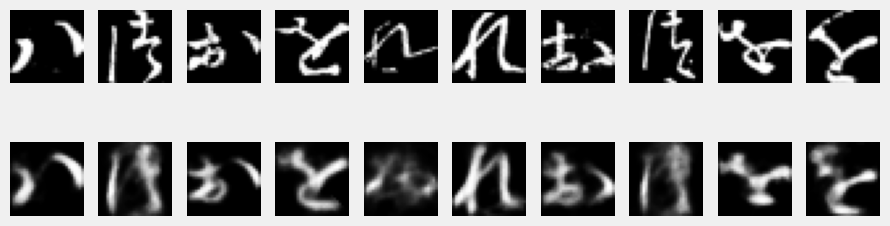

In [7]:
model.eval()
dataiter = iter(train_loader)
images, _ = next(dataiter)

images = images.view(-1, 28 * 28).to(device)
reconstructed = model(images)

fig, axes = plt.subplots(nrows=2, ncols=10, figsize=(10, 3))
for i in range(10):
    axes[0, i].imshow(images[i].cpu().detach().numpy().reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(reconstructed[i].cpu().detach().numpy().reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')
plt.show()

### 1.2 Variational Autoencoders (VAE)


### 1.3 Denoising Autoencoders (DAE)

In [ ]:
def add_noise(data , noise_factor =0.5):
noisy_data = data + noise_factor * torch.randn_like(data)
return torch.clamp(noisy_data , 0., 1.)

### 1.4 Training and Loss Curves

### 1.5 Evaluation and t-SNE Visualization

### 1.6 Transfer Learning and Classification

### 1.7 EXTRA: STL-10 Dataset Adaptation

## Part II: Object Detection

### Part II-A: YOLO Evaluation on MID-3K Dataset

#### 2.1 Data Configuration
*Preparação dos ficheiros YAML para os splits Random e DEEC_DEI.*

#### 2.2 Training from Scratch
*Treino de duas arquiteturas YOLO diferentes (ex: YOLOv8s e YOLOv10s) a partir do zero durante 25 épocas.*

#### 2.3 Training with Pretrained Checkpoints
*Treino das mesmas duas arquiteturas YOLO partindo de pesos pré-treinados durante 25 épocas.*

#### 2.4 Loss Curves and Evaluation Metrics
*Recolha de curvas de loss e avaliação dos modelos nos test sets.*

### Part II-B: Unique Object Counting

#### 2.5 Video Sequence Processing and Object Re-identification
*Pipeline para identificar e contar instâncias únicas de objetos num vídeo capturado.*